In [1]:
import random # Usamos la librería básica de Python
import matplotlib.pyplot as plt # Solo para dibujar, no hace cálculos

print("==================================================")
print("LABORATORIO: IA 1 - Búsqueda de b y w con Estructuras Básicas")
print("==================================================\n")

# =================================================================
# 1. EL DATASET
# =================================================================
# x = Horas de estudio
x = [1,   1.5,  2,    3.5,  4,    5,    5.5,  6,    7.5,  8,    9,    10]
# y = Nota del examen real
y = [23.5, 28.0, 31.0, 42.5, 47.0, 54.5, 59.0, 62.5, 76.0, 78.5, 87.0, 96.5]

print("Dataset cargado:")
print(f"Horas (x): {x}")
print(f"Notas (y): {y}\n")



LABORATORIO: IA 1 - Búsqueda de b y w con Estructuras Básicas

Dataset cargado:
Horas (x): [1, 1.5, 2, 3.5, 4, 5, 5.5, 6, 7.5, 8, 9, 10]
Notas (y): [23.5, 28.0, 31.0, 42.5, 47.0, 54.5, 59.0, 62.5, 76.0, 78.5, 87.0, 96.5]



In [2]:
# =================================================================
# 2. EL ALGORITMO BÁSICO (Estructuras repetitivas y decisivas)
# =================================================================
# Variables para guardar a los ganadores
mejor_error = float('inf')
mejor_b = 0
mejor_w = 0

iteraciones = 10000

# ESTRUCTURA REPETITIVA 1: Repetir el experimento miles de veces
for i in range(iteraciones):
    
    # La computadora adivina números al azar para b y w
    b_rand = random.uniform(0, 30)
    w_rand = random.uniform(0, 15)
    
    suma_errores_cuadrados = 0
    
    # ESTRUCTURA REPETITIVA 2: Recorrer cada estudiante uno por uno
    for j in range(len(x)):
        # Calculamos la y inventada: y = b + wx
        y_prediccion = b_rand + (w_rand * x[j])
        
        # Calculamos el error de este estudiante y lo elevamos al cuadrado
        error_estudiante = y[j] - y_prediccion
        suma_errores_cuadrados = suma_errores_cuadrados + (error_estudiante ** 2)
    
    # Calculamos el promedio del error (MSE)
    error_promedio = suma_errores_cuadrados / len(x)
    
    # ESTRUCTURA DECISIVA: Preguntamos si este error es el mejor hasta ahora
    if error_promedio < mejor_error:
        mejor_error = error_promedio
        mejor_b = b_rand
        mejor_w = w_rand

print("--- RESULTADOS DEL ALGORITMO ---")
print(f"Mejor valor de b (Intersección): {mejor_b:.4f}")
print(f"Mejor valor de w (Pendiente): {mejor_w:.4f}")
print(f"Ecuación encontrada: y = {mejor_b:.2f} + {mejor_w:.2f}x")
print(f"Error mínimo logrado: {mejor_error:.4f}\n")



--- RESULTADOS DEL ALGORITMO ---
Mejor valor de b (Intersección): 14.5473
Mejor valor de w (Pendiente): 8.1353
Ecuación encontrada: y = 14.55 + 8.14x
Error mínimo logrado: 0.5251



In [3]:

# =================================================================
# 3. INFERENCIAS PARA 10 NUEVOS VALORES
# =================================================================
print("--- 10 INFERENCIAS CON LA ECUACIÓN ---")
# 10 valores nuevos de x (horas)
x_nuevos = [0, 0.5, 2.5, 3.8, 4.2, 6.5, 7.2, 8.5, 11, 15]

# ESTRUCTURA REPETITIVA 3: Recorrer los valores nuevos
for x_val in x_nuevos:
    # Usamos los mejores b y w encontrados
    y_inferida = mejor_b + (mejor_w * x_val)
    
    # ESTRUCTURA DECISIVA 2: Limitar la nota entre 0 y 100
    if y_inferida > 100:
        y_inferida = 100
    if y_inferida < 0:
        y_inferida = 0
        
    print(f"Para x = {x_val:4.1f} horas de estudio  =>  y = {y_inferida:.2f} puntos")




--- 10 INFERENCIAS CON LA ECUACIÓN ---
Para x =  0.0 horas de estudio  =>  y = 14.55 puntos
Para x =  0.5 horas de estudio  =>  y = 18.61 puntos
Para x =  2.5 horas de estudio  =>  y = 34.89 puntos
Para x =  3.8 horas de estudio  =>  y = 45.46 puntos
Para x =  4.2 horas de estudio  =>  y = 48.72 puntos
Para x =  6.5 horas de estudio  =>  y = 67.43 puntos
Para x =  7.2 horas de estudio  =>  y = 73.12 puntos
Para x =  8.5 horas de estudio  =>  y = 83.70 puntos
Para x = 11.0 horas de estudio  =>  y = 100.00 puntos
Para x = 15.0 horas de estudio  =>  y = 100.00 puntos


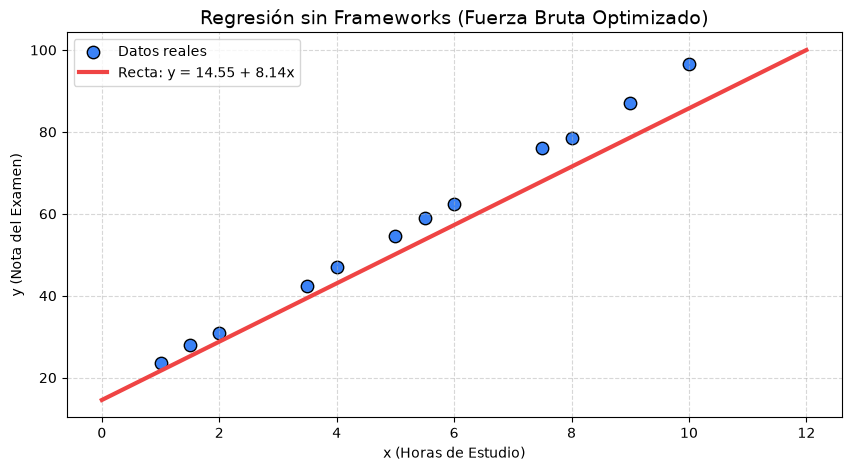

In [4]:
# =================================================================
# 4. GRÁFICA VISUAL (Opcional pero recomendada para mostrar resultados)
# =================================================================
plt.figure(figsize=(10, 5))
plt.scatter(x, y, color='#3b82f6', s=80, edgecolors='black', label='Datos reales')

# Crear puntos para la línea recta
x_linea = [0, 12]
y_linea = [mejor_b + (mejor_w * 0), mejor_b + (mejor_w * 12)]

# Asegurar que la línea visual no pase de 100
if y_linea[1] > 100: y_linea[1] = 100

plt.plot(x_linea, y_linea, color='#ef4444', linewidth=3, label=f'Recta: y = {mejor_b:.2f} + {mejor_w:.2f}x')
plt.title('Regresión sin Frameworks (Fuerza Bruta Optimizado)', fontsize=14)
plt.xlabel('x (Horas de Estudio)')
plt.ylabel('y (Nota del Examen)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()